# GridSearchCV — Ridge

Notebook independente: execute as células em ordem. Aqui estão apenas a preparação e a análise do **Ridge**. Para comparar os três modelos com as mesmas métricas, abra `02_GridSearchCV.ipynb`.


## 1. Importações e dados

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    PowerTransformer,
    StandardScaler,
    QuantileTransformer,
)

# Localiza Regularização ao executar da raiz do workspace, do projeto ou de notebooks.
PASTA_ATUAL = Path.cwd().resolve()
PASTA_PROJETO = next(
    pasta
    for base in (PASTA_ATUAL, *PASTA_ATUAL.parents)
    for pasta in (base, base / "Regularização")
    if (pasta / "src" / "config.py").is_file()
    and (pasta / "dados" / "diabetes_categorizado.parquet").is_file()
)
if str(PASTA_PROJETO) not in sys.path:
    sys.path.insert(0, str(PASTA_PROJETO))

from src.utils import dataframe_coeficientes
from src.config import DADOS_DIABETES_CATEGORIZADOS
from src.graficos import plot_comparar_metricas_modelos, plot_coeficientes
from src.modelos import (
    RANDOM_STATE,
    grid_search_cv_regressor,
    organiza_resultados,
    construir_pipeline_modelo_regressao,
)

sns.set_theme(palette="bright")

In [2]:
df = pd.read_parquet(DADOS_DIABETES_CATEGORIZADOS)

df.head()

,idade,sexo,imc,pressao_media,colesterol_total,ldl,hdl,triglicerides,glicose,target,colesterol_hdl_cat
0,59,2,32.099998,101.0,157,93.199997,38.0,4.8598,87,151,4-5
1,48,1,21.600000,87.0,183,103.199997,70.0,3.8918,69,75,2-3
2,72,2,30.500000,93.0,156,93.599998,41.0,4.6728,85,141,4-5
3,24,1,25.299999,84.0,198,131.399994,40.0,4.8903,89,206,4-5
4,50,1,23.000000,101.0,192,125.400002,52.0,4.2905,80,135,4-5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   idade               442 non-null    int8    
 1   sexo                442 non-null    int8    
 2   imc                 442 non-null    float32 
 3   pressao_media       442 non-null    float32 
 4   colesterol_total    442 non-null    int16   
 5   ldl                 442 non-null    float32 
 6   hdl                 442 non-null    float32 
 7   triglicerides       442 non-null    float32 
 8   glicose             442 non-null    int8    
 9   target              442 non-null    int16   
 10  colesterol_hdl_cat  442 non-null    category
dtypes: category(1), float32(5), int16(2), int8(3)
memory usage: 12.3 KB


In [4]:
X = df.drop(columns="target")
y = df["target"]

## 2. Pré-processamento compartilhado

Os três modelos testam os mesmos três pré-processadores e a mesma opção de transformar o alvo. As transformações ficam dentro do pipeline: são ajustadas apenas nos dados de treino de cada divisão, evitando vazamento de dados.

In [5]:
colunas_power_transform = ["imc", "ldl", "hdl", "colesterol_total"]

coluna_target = ["target"]

coluna_ordinal_encoder = ["colesterol_hdl_cat"]

coluna_one_hot_encoder = ["sexo"]

colunas_standard_scaler = [
    coluna
    for coluna in df.columns
    if coluna not in colunas_power_transform + coluna_target + coluna_ordinal_encoder + coluna_one_hot_encoder
]

colunas_standard_scaler

['idade', 'pressao_media', 'triglicerides', 'glicose']

In [6]:
categorias_ordinal_encoder = [
    ["2-3", "4-5", "6+"],
]

In [7]:
preprocessamento_categoricas = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ],
    remainder="passthrough",
)

preprocessamento_simples = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
        ("standard_scaler", StandardScaler(), X.columns.difference(coluna_ordinal_encoder + coluna_one_hot_encoder)),
    ],
    remainder="passthrough",
)

preprocessamento_completo = ColumnTransformer(
    [
        ("power_transform", PowerTransformer(method="box-cox"), colunas_power_transform),
        ("standard_scaler", StandardScaler(), colunas_standard_scaler),
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ]
)

target_transformer = QuantileTransformer(n_quantiles=20, output_distribution="normal", random_state=RANDOM_STATE)

## 3. Regras comuns das buscas

`alpha` controla a intensidade da regularização. Todos testam os mesmos valores; ElasticNet testa também `l1_ratio`.

A função `grid_search_cv_regressor` usa cinco divisões com embaralhamento e semente fixa, calcula R², MAE e RMSE e escolhe pelo **menor RMSE**. No scikit-learn os erros são armazenados com sinal negativo: `best_score_` é o RMSE negativo. Nas tabelas abaixo, MAE e RMSE aparecem positivos.

As buscas nesta etapa usam todos os dados para explorar configurações e coeficientes. Seus melhores escores não são uma avaliação independente; essa avaliação vem na seção final.

In [8]:
ALPHAS = [0.01, 0.05, 0.1, 1.0, 5.0, 10.0]
PREPROCESSADORES = [
    preprocessamento_categoricas,
    preprocessamento_simples,
    preprocessamento_completo,
]
TRANSFORMADORES_ALVO = [target_transformer, None]

# As mesmas divisões externas serão usadas por todos na comparação final.
cv_externa = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
METRICAS = ["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"]

## 4. Busca e análise — Ridge

A penalização L2 reduz a magnitude dos coeficientes.

Seguimos os mesmos passos: definir a grade, treinar a busca, examinar os candidatos e visualizar os coeficientes.

In [9]:
# 1. Grade exclusiva do Ridge; as opções comuns são iguais nos três modelos.
param_grid_ridge = {
    "regressor__reg__alpha": ALPHAS,
    "regressor__preprocessor": PREPROCESSADORES,
    "transformer": TRANSFORMADORES_ALVO,
}

# Mantemos o wrapper do alvo mesmo quando a grade escolhe transformer=None.
grid_search_ridge = grid_search_cv_regressor(
    regressor=Ridge(),
    param_grid=param_grid_ridge,
    preprocessor=preprocessamento_categoricas,
    target_transformer=target_transformer,
)

In [10]:
# 2. Ajusta cada configuração por validação cruzada e reajusta a melhor em X, y.
grid_search_ridge.fit(X, y)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                                             ColumnTransformer(remainder='passthrough',
                                                                                               transformers=[('ordinal_encoder',
                                                                                                              OrdinalEncoder(categories=[['2-3',
                                                                                                                                          '4-5',
                                                                                                                                          '6+']]),
                                                                                                              ['colesterol_hdl_cat']),
                                                                                                             ('one_hot_encoder',
                                                                                                              OneHotEncoder(drop='if_binary'),
                                                                                                              ['sexo'])]...
                                                                                      ['colesterol_hdl_cat']),
                                                                                     ('one_hot_encoder',
                                                                                      OneHotEncoder(drop='if_binary'),
                                                                                      ['sexo'])])],
                         'regressor__reg__alpha': [0.01, 0.05, 0.1, 1.0, 5.0,
                                                   10.0],
                         'transformer': [QuantileTransformer(n_quantiles=20,
                                                             output_distribution='normal',
                                                             random_state=42),
                                         None]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [11]:
# 3. Parâmetros escolhidos e RMSE médio da busca (positivo).
print("Melhores parâmetros:", grid_search_ridge.best_params_)
print(f"RMSE médio da busca: {-grid_search_ridge.best_score_:.3f}")
grid_search_ridge.best_estimator_

Melhores parâmetros: {'regressor__preprocessor': ColumnTransformer(remainder='passthrough',
                  transformers=[('ordinal_encoder',
                                 OrdinalEncoder(categories=[['2-3', '4-5',
                                                             '6+']]),
                                 ['colesterol_hdl_cat']),
                                ('one_hot_encoder',
                                 OneHotEncoder(drop='if_binary'), ['sexo']),
                                ('standard_scaler', StandardScaler(),
                                 Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))]), 'regressor__reg__alpha': 0.1, 'transformer': None}
RMSE médio da busca: 54.645


TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(remainder='passthrough',
                                                                        transformers=[('ordinal_encoder',
                                                                                       OrdinalEncoder(categories=[['2-3',
                                                                                                                   '4-5',
                                                                                                                   '6+']]),
                                                                                       ['colesterol_hdl_cat']),
                                                                                      ('one_hot_encoder',
                                                                                       OneHotEncoder(drop='if_binary'),
                                                                                       ['sexo']),
                                                                                      ('standard_scaler',
                                                                                       StandardScaler(),
                                                                                       Index(['colesterol_total', 'glicose', 'hdl', 'idade', 'imc', 'ldl',
       'pressao_media', 'triglicerides'],
      dtype='object'))])),
                                                     ('reg',
                                                      Ridge(alpha=0.1))]))

In [12]:
# 4. Candidatos ordenados pelo RMSE; rank 1 indica a melhor configuração.
df_busca_ridge = pd.DataFrame(grid_search_ridge.cv_results_)
df_busca_ridge["MAE"] = -df_busca_ridge["mean_test_neg_mean_absolute_error"]
df_busca_ridge["RMSE"] = -df_busca_ridge["mean_test_neg_root_mean_squared_error"]
df_busca_ridge.sort_values("rank_test_neg_root_mean_squared_error")[[
    "params", "mean_test_r2", "MAE", "RMSE",
    "std_test_neg_root_mean_squared_error",
]].head(10)

,params,mean_test_r2,MAE,RMSE,std_test_neg_root_mean_squared_error
17,{'regressor__preprocessor': ColumnTransformer(...,0.482483,44.105397,54.644877,2.533853
15,{'regressor__preprocessor': ColumnTransformer(...,0.482471,44.106037,54.645202,2.536961
5,{'regressor__preprocessor': ColumnTransformer(...,0.482469,44.105765,54.645514,2.532374
13,{'regressor__preprocessor': ColumnTransformer(...,0.482459,44.106564,54.645521,2.539540
3,{'regressor__preprocessor': ColumnTransformer(...,0.482463,44.106228,54.645530,2.536262
1,{'regressor__preprocessor': ColumnTransformer(...,0.482458,44.106604,54.645589,2.539407
19,{'regressor__preprocessor': ColumnTransformer(...,0.482523,44.110622,54.647397,2.493960
7,{'regressor__preprocessor': ColumnTransformer(...,0.482398,44.118945,54.654238,2.469614
21,{'regressor__preprocessor': ColumnTransformer(...,0.482012,44.184077,54.680503,2.445104
23,{'regressor__preprocessor': ColumnTransformer(...,0.481588,44.265751,54.703714,2.441492


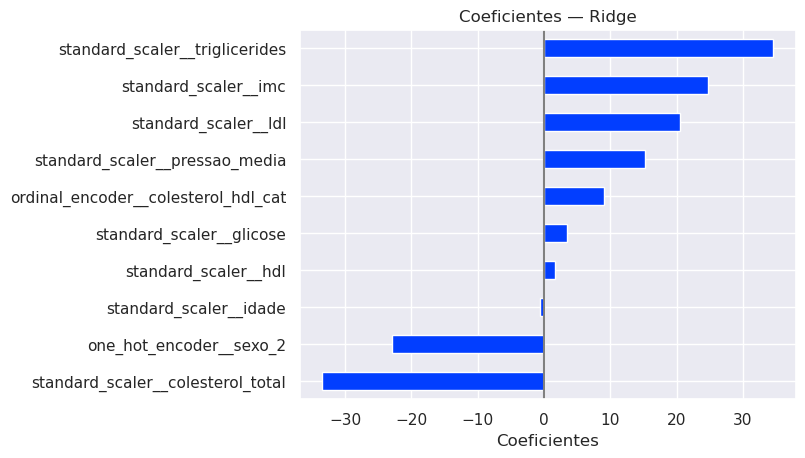

,coeficiente
standard_scaler__colesterol_total,-33.468933
one_hot_encoder__sexo_2,-22.981237
standard_scaler__idade,-0.621727
standard_scaler__hdl,1.713571
standard_scaler__glicose,3.474370
ordinal_encoder__colesterol_hdl_cat,9.040850
standard_scaler__pressao_media,15.177413
standard_scaler__ldl,20.488815
standard_scaler__imc,24.697460
standard_scaler__triglicerides,34.557255


In [13]:
# 5. Coeficientes do modelo reajustado, com os nomes das variáveis transformadas.
melhor_ridge = grid_search_ridge.best_estimator_
pipeline_ridge = melhor_ridge.regressor_
df_coeficientes_ridge = dataframe_coeficientes(
    pipeline_ridge["reg"].coef_,
    pipeline_ridge["preprocessor"].get_feature_names_out(),
)
plot_coeficientes(df_coeficientes_ridge, tituto="Coeficientes — Ridge")
df_coeficientes_ridge

## 5. Como ler os resultados

- A busca escolhe o menor RMSE médio; `best_score_` guarda esse erro com sinal negativo.
- A tabela mostra R², MAE e RMSE dos candidatos; MAE e RMSE estão positivos.
- O gráfico mostra os coeficientes após o pré-processamento escolhido.
- Esses resultados foram usados para escolher parâmetros. A avaliação independente por validação cruzada aninhada está no notebook de comparação `02_GridSearchCV.ipynb`.
